<a href="https://colab.research.google.com/github/tusharguleria542/Statistics-Practical/blob/main/practical_2_Tushar_Guleria_GF202459441.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Practical 2**

Use the rating dataset of professors of USA top universities and answer the following:

 Q1. Can you identify whether teachers Rating Data is a time serires or cross sectional?

 Q2. Find the mean, median, minimum and maximum values for the students.

  Q3. Produce the descriptive statistics table.
  
   Q4. Create a histogram of the beauty variable and breifly comment on the distribution of the data.
   
   Q5. Does average beauty score differ by gender? Produce the means and standard deviations for both male and female instructors.
   
   Q6. Calculate the percentage of males and females that are tenured professors. Will you say that tenure status differ by gender?
   
   *italicized text* PS. Please read the questions carefully to understand which rating dataset to be used.

# Importing the essential libraries

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


#Load the dataset directly into a Pandas DataFrame.

In [ ]:
df = pd.read_csv('TeachingRatings.csv')
df.head()


,rownames,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,1,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1
1,2,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2
2,3,no,51,male,more,-0.571984,3.7,upper,yes,yes,55,55,3
3,4,no,40,female,more,-0.677963,4.3,upper,yes,yes,40,46,4
4,5,no,31,female,more,1.509794,4.4,upper,yes,yes,42,48,5


#Q1. Can you identify whether teachers Rating Data is a time serires or cross sectional?

Answer : The Teacher Ratings dataset is cross-sectional data.

Reason: It collects observations across multiple distinct instructors and courses evaluated at a single point in time (or aggregated without tracking sequential time intervals).

It is not a time-series dataset because it does not record sequential, chronological measurements of a single subject over regular intervals (e.g., daily, monthly, or yearly).

#Q2. Find the mean, median, minimum and maximum values for the students.


In [ ]:
# Calculate mean, median, min, max for 'students'
students_mean = df["students"].mean()
students_median = df["students"].median()
students_min = df["students"].min()
students_max = df["students"].max()

print(f"Mean: {students_mean:.2f}")
print(f"Median: {students_median:.2f}")
print(f"Minimum: {students_min}")
print(f"Maximum: {students_max}")

Mean: 36.62
Median: 23.00
Minimum: 5
Maximum: 380


#Q3. Produce the descriptive statistics table


In [ ]:
# Produce descriptive statistics summary table
desc_table = df.describe()
desc_table


,rownames,age,beauty,eval,students,allstudents,prof
count,463.000000,463.000000,4.630000e+02,463.000000,463.000000,463.000000,463.000000
mean,232.000000,48.365011,6.263499e-08,3.998272,36.624190,55.177106,45.434125
std,133.800847,9.802742,7.886477e-01,0.554866,45.018481,75.072800,27.508902
min,1.000000,29.000000,-1.450494e+00,2.100000,5.000000,8.000000,1.000000
25%,116.500000,42.000000,-6.562689e-01,3.600000,15.000000,19.000000,20.000000
50%,232.000000,48.000000,-6.801430e-02,4.000000,23.000000,29.000000,44.000000
75%,347.500000,57.000000,5.456024e-01,4.400000,40.000000,60.000000,70.500000
max,463.000000,73.000000,1.970023e+00,5.000000,380.000000,581.000000,94.000000


#Q4. Create a histogram of the beauty variable and breifly comment on the distribution of the data


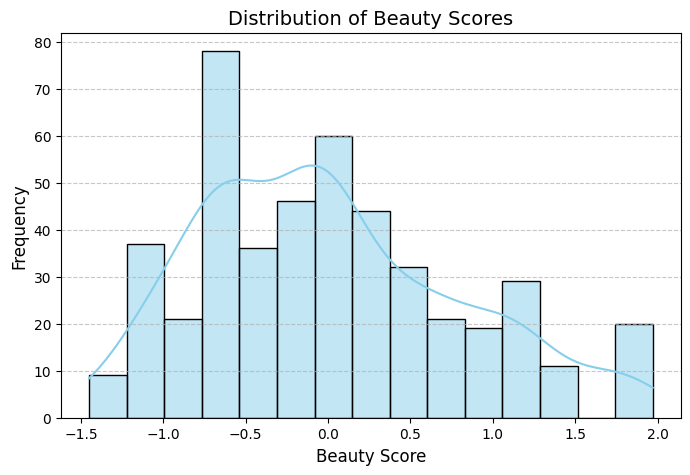

In [ ]:
#  Create histogram of beauty variable
plt.figure(figsize=(8, 5))
sns.histplot(df["beauty"], kde=True, bins=15, color="skyblue", edgecolor="black")
plt.title("Distribution of Beauty Scores", fontsize=14)
plt.xlabel("Beauty Score", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

#Q5. Does average beauty score differ by gender? Produce the means and standard deviations for both male and female instructors.

In [ ]:
#  Mean and Standard Deviation of beauty by gender
beauty_by_gender = df.groupby("gender")["beauty"].agg(["count", "mean", "std"])
print(beauty_by_gender)

        count      mean      std
gender                          
female    195  0.116109  0.81781
male      268 -0.084482  0.75713


#Q6. Calculate the percentage of males and females that are tenured professors. Will you say that tenure status differ by gender?

In [ ]:
#  Tenure percentage calculation
tenure_crosstab = pd.crosstab(
    df["gender"], df["tenure"], normalize="index"
) * 100
print("Tenure Percentage by Gender (%):")
print(tenure_crosstab)

#  Chi-square test for statistical significance
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(df["gender"], df["tenure"])
chi2, p_val, _, _ = chi2_contingency(contingency_table)
print(f"\nChi-square test p-value: {p_val:.4f}")

Tenure Percentage by Gender (%):
tenure         no        yes
gender                      
female  25.641026  74.358974
male    19.402985  80.597015

Chi-square test p-value: 0.1374
